<a href="https://colab.research.google.com/github/Khushal-Sonar/Machine_Learning_Lab/blob/main/Practical_8_Short.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
# DNN for Digit Classification using Keras

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

In [36]:
# 1. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

Training: (60000, 28, 28)
Testing: (10000, 28, 28)


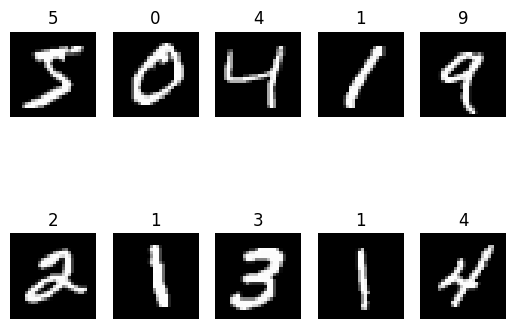

In [37]:
# 2. Display Sample Images
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

In [38]:
# 3. Normalize Data
x_train = x_train / 255.0
x_test = x_test / 255.0

In [39]:

# 4. Build 3-Layer DNN
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [40]:
# 5. Display Model Architecture
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# 6. Compile Model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [42]:
# 7. Train Model
history = model.fit(x_train, y_train,
                    epochs=5, batch_size=32,
                    validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9229 - loss: 0.2602 - val_accuracy: 0.9680 - val_loss: 0.1089
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9661 - loss: 0.1088 - val_accuracy: 0.9720 - val_loss: 0.0927
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9763 - loss: 0.0738 - val_accuracy: 0.9750 - val_loss: 0.0964
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9822 - loss: 0.0562 - val_accuracy: 0.9787 - val_loss: 0.0772
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9853 - loss: 0.0458 - val_accuracy: 0.9763 - val_loss: 0.0933


In [43]:
# 8. Evaluate Model
loss, acc = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9739 - loss: 0.0903
Test Loss: 0.09029168635606766
Test Accuracy: 0.9739000201225281


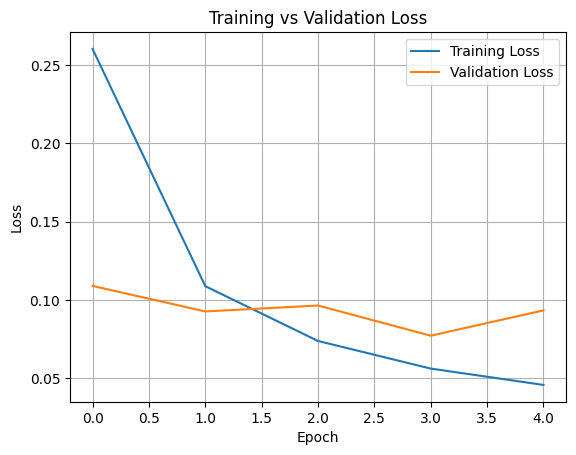

In [44]:
# 9. Plot Training and Validation Loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

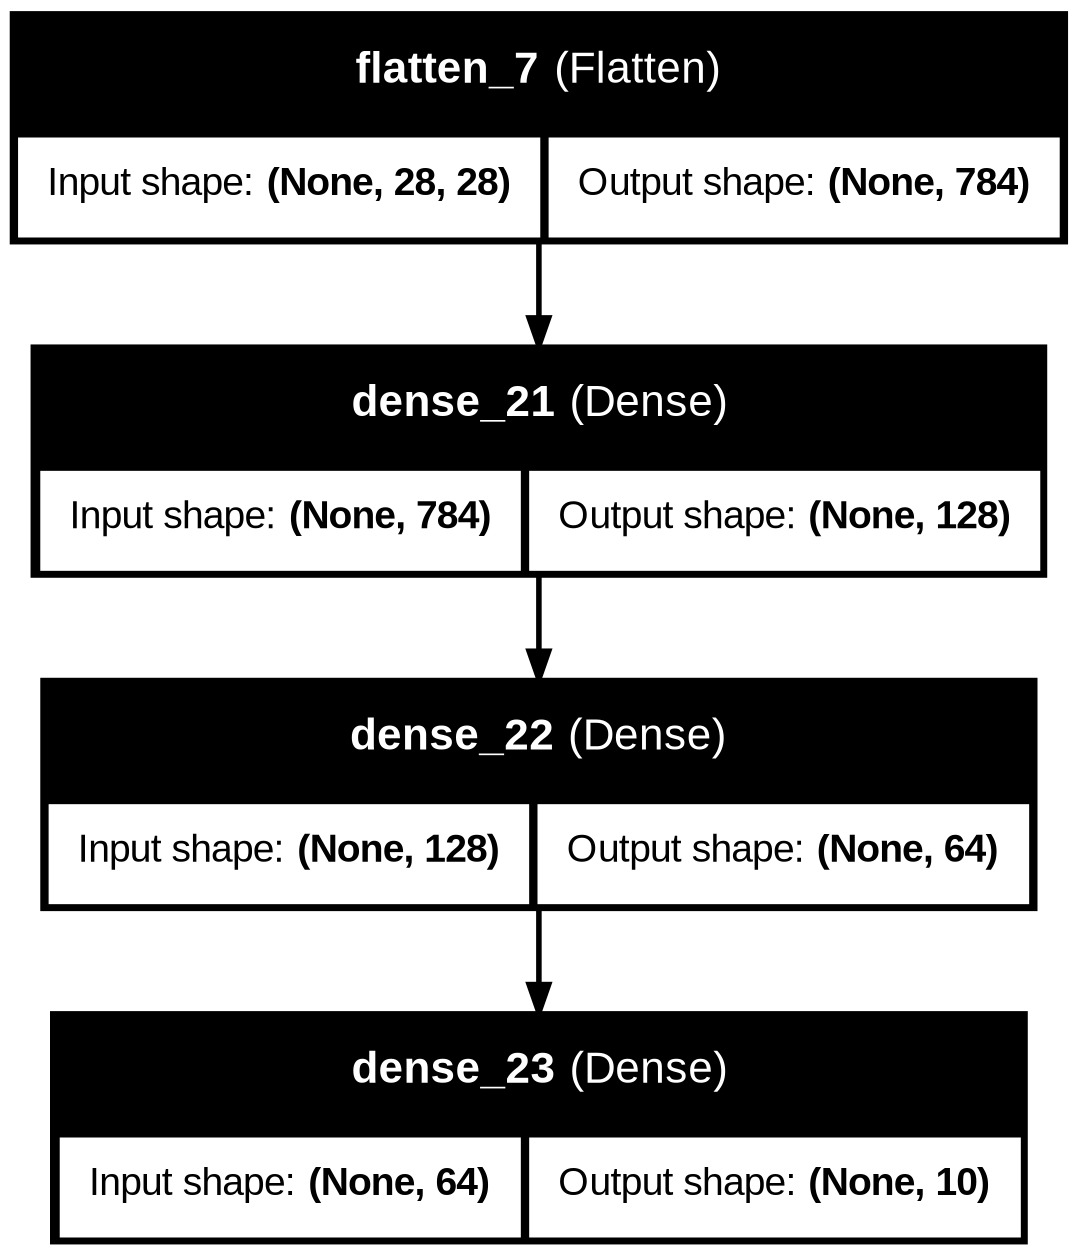

In [46]:
# 10. Visualize Network Architecture
tf.keras.utils.plot_model(model, show_shapes=True,
                           show_layer_names=True,
                           to_file="dnn_architecture.png")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


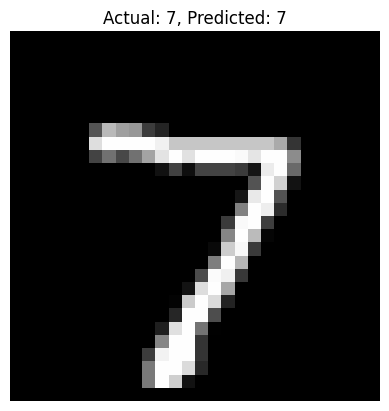

In [47]:
# 11. Predict Sample Digit
p = model.predict(x_test[:1])
digit = np.argmax(p[0])

plt.imshow(x_test[0], cmap="gray")
plt.title(f"Actual: {y_test[0]}, Predicted: {digit}")
plt.axis("off")
plt.show()